# Georgina Gidgee Woodlands — SDM Workflow

Species: Georgina gidgee (*Acacia georginae* F.M.Bailey)
Occurrence data: `SpeciesOccurence_clean.csv` (TERN / ALA, accessed 22-Mar-2014)

Study area: IBRA 7 selected bioregions — BRT, MGD, CHC, MII, DEU, MUL, DMR, SSD, FIN, STP, GSD, TAN, MAC
(not yet applied as a spatial clip in this draft — see note in Section 1)

## 1. SDM — MaxEnt (current climate)

In [30]:
options(java.parameters = "-Xmx8g")  # must be set before rJava/dismo starts the JVM

library(readr)
library(dplyr)
library(raster)
library(dismo)
library(maps)
library(leaflet)

t_start <- Sys.time()

In [31]:
# --- Step 1: config ----------------------------------------------------------
set.seed(1964)  # reproducibility for R-side sampling (e.g. Step 10 background draw)

base_dir     <- "/Users/ecocommons/Downloads/02_EIW/Test_workflow/Gidgee/IUCNGeorginaGidgee"
baseline_dir <- file.path(base_dir, "Baseline", "2000")
species_name <- "Acacia georginae"

preview_dir       <- "output/00_raster_preview"
maxent_output_dir <- "output/01_current_maxent"
dir.create(preview_dir, recursive = TRUE, showWarnings = FALSE)
dir.create(maxent_output_dir, recursive = TRUE, showWarnings = FALSE)

Step 2: occurrence loaded, nrow(occ) = 272 


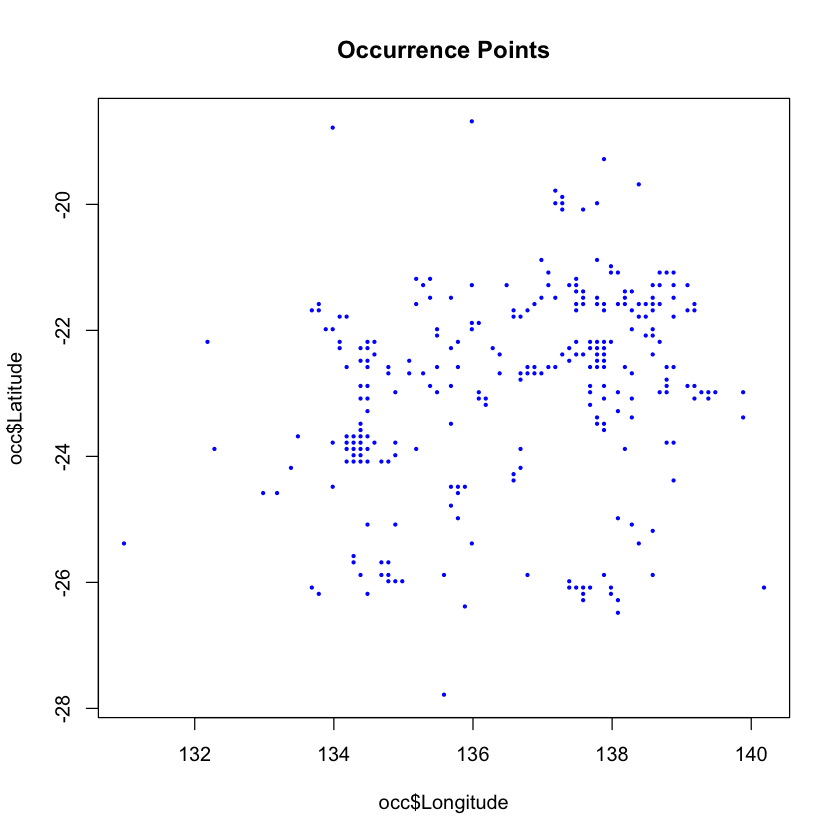

In [33]:
# --- Step 2: load & clean occurrence points -----------------------------------
occ <- read_csv(
  file.path(base_dir, "SpeciesOccurence_clean.csv"),
  show_col_types = FALSE
) %>%
  filter(Species == species_name) %>%
  dplyr::select(Longitude, Latitude) %>%
  distinct() %>%
  filter(!is.na(Longitude), !is.na(Latitude))

cat("Step 2: occurrence loaded, nrow(occ) =", nrow(occ), "\n")
plot(occ$Longitude, occ$Latitude, pch = 20, cex = 0.5, col = "blue", main = "Occurrence Points")

In [ ]:
# --- Step 3: predictor stack (specific bioclim subset, not all 19) + PNG preview ---
raster_paths <- c(
  file.path(baseline_dir, "soil.asc"),
  file.path(baseline_dir, "ibra.asc"),
  file.path(baseline_dir, "bioclim_01.asc"),
  file.path(baseline_dir, "bioclim_04.asc"),
  file.path(baseline_dir, "bioclim_05.asc"),
  file.path(baseline_dir, "bioclim_06.asc"),
  file.path(baseline_dir, "bioclim_07.asc"),
  file.path(baseline_dir, "bioclim_12.asc"),
  file.path(baseline_dir, "bioclim_13.asc"),
  file.path(baseline_dir, "bioclim_14.asc"),
  file.path(baseline_dir, "bioclim_15.asc")
)

raster_stack <- stack(raster_paths)
names(raster_stack) <- gsub("\\.asc$", "", basename(raster_paths))
for (nm in names(raster_stack)) {
  png(file.path(preview_dir, paste0(nm, ".png")), width = 1200, height = 1000, res = 150)
  plot(raster_stack[[nm]], main = nm)
  maps::map("world", regions = "Australia", add = TRUE, col = "grey60", border = "grey40")
  dev.off()
}
cat("Step 3: predictor stack built, preview PNGs written to", preview_dir, "\n")
plot(raster_stack)

Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”
Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" 

class      : RasterStack 
dimensions : 691, 886, 612226, 11  (nrow, ncol, ncell, nlayers)
resolution : 0.05, 0.05  (x, y)
extent     : 111.975, 156.275, -44.525, -9.975  (xmin, xmax, ymin, ymax)
crs        : +proj=longlat +datum=WGS84 +no_defs 
names      : soil, ibra, bioclim_01, bioclim_04, bioclim_05, bioclim_06, bioclim_07, bioclim_12, bioclim_13, bioclim_14, bioclim_15 


Step 3b: cropped to study extent ( 128.98, 142.18, -29.78, -16.68 )


class      : RasterBrick 
dimensions : 262, 264, 69168, 11  (nrow, ncol, ncell, nlayers)
resolution : 0.05, 0.05  (x, y)
extent     : 128.975, 142.175, -29.775, -16.675  (xmin, xmax, ymin, ymax)
crs        : +proj=longlat +datum=WGS84 +no_defs 
source     : memory
names      : soil, ibra, bioclim_01, bioclim_04, bioclim_05, bioclim_06, bioclim_07, bioclim_12, bioclim_13, bioclim_14, bioclim_15 
min values :    1,    8,        172,       2670,        336,          4,        179,        127,         15,          0,         16 
max values :   14,   57,        279,       6328,        394,        158,        345,       1219,        315,         18,        126 


agg_record_670069248 
                   2

Step 3b: study_area_extent.png written


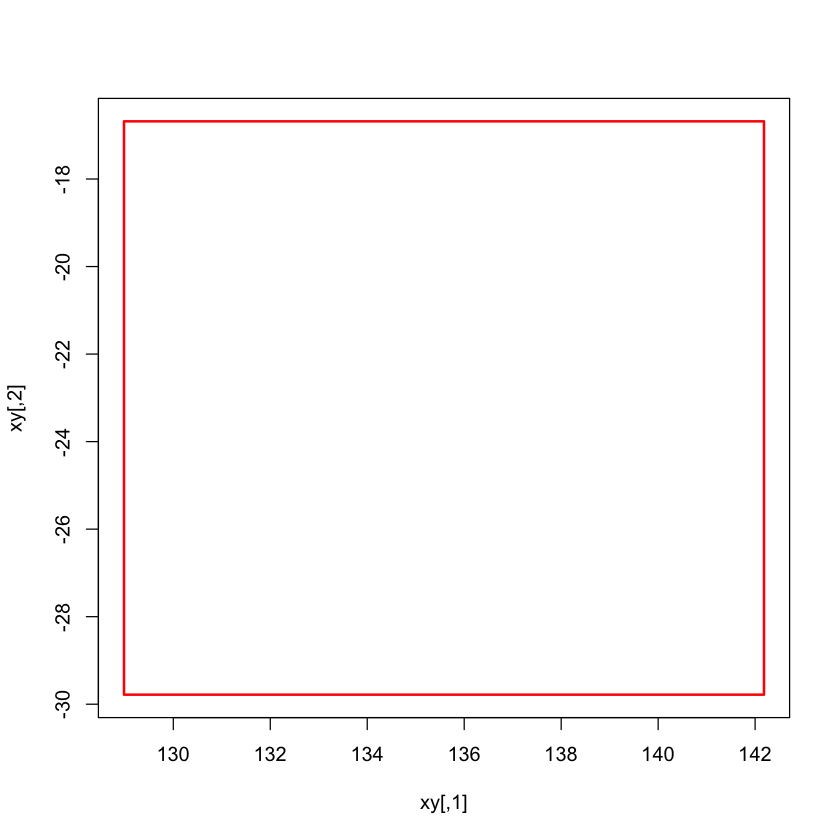

In [36]:
# --- Step 3b: study area extent ------------------------------------------------
# Official study area = union of these 13 IBRA7 subregions:
ibra7_regions <- c(
  BRT = "Burt Plain",              MGD = "Mitchell Grass Downs",
  CHC = "Channel Country",         MII = "Mount Isa Inlier",
  DEU = "Desert Uplands",          MUL = "Mulga Lands",
  DMR = "Davenport Murchison Ranges", SSD = "Simpson Strzelecki Dunefields",
  FIN = "Finke",                   STP = "Stony Plains",
  GSD = "Great Sandy Desert",      TAN = "Tanami",
  MAC = "MacDonnell Ranges"
)
# NOTE: ibra.asc holds 87 arbitrary integer codes with no legend/attribute
# table in this data package, so the exact codes for these 13 regions can't
# be recovered from the raster alone (see chat). Using a buffered bounding
# box around the occurrence records as a practical stand-in study extent
# until the actual IBRA7 polygons (with REG_CODE_7) are available to crop by
# name properly.
buffer_deg <- 2   # ~200 km padding around the occurrence records

study_extent <- extent(
  min(occ$Longitude) - buffer_deg, max(occ$Longitude) + buffer_deg,
  min(occ$Latitude)  - buffer_deg, max(occ$Latitude)  + buffer_deg
)

raster_stack <- crop(raster_stack, study_extent)
cat("Step 3b: cropped to study extent (", paste(round(as.vector(study_extent), 2), collapse = ", "), ")\n")
raster_stack

png(file.path(preview_dir, "study_area_extent.png"), width = 1200, height = 1000, res = 150)
maps::map("world", regions = "Australia", col = "grey85", fill = TRUE, border = "grey50",
          xlim = c(study_extent@xmin - 3, study_extent@xmax + 3),
          ylim = c(study_extent@ymin - 3, study_extent@ymax + 3))
plot(study_extent, add = TRUE, col = "red", lwd = 2)
points(occ$Longitude, occ$Latitude, pch = 20, col = adjustcolor("darkgreen", 0.5), cex = 0.6)
title("Study area extent vs. occurrence records\n(bbox proxy for the 13 IBRA7 regions - see note in script)")
dev.off()
cat("Step 3b: study_area_extent.png written\n")
plot(study_extent, col = "red", lwd = 2)


In [37]:
# --- Step 4: ibra and soil are region/class codes -> treat as categorical ----
raster_stack$ibra <- as.factor(raster_stack$ibra)
raster_stack$soil <- as.factor(raster_stack$soil)

# --- Step 5: drop occurrence points that fall outside the raster / on NA cells ---
occ_vals <- raster::extract(raster_stack[[1]], occ)
occ <- occ[!is.na(occ_vals), ]
cat("Step 5: after NA-drop, nrow(occ) =", nrow(occ), "\n")


Step 5: after NA-drop, nrow(occ) = 272 


In [38]:
# --- Step 6: fit MaxEnt -------------------------------------------------------
t0 <- Sys.time()
mx <- maxent(
  x       = raster_stack,
  p       = as.data.frame(occ),
  factors = c("ibra", "soil"),   # dismo drops factor-ness on extract() otherwise
  path    = maxent_output_dir,
  args = c(
    "autofeature=true",
    "linear=true", "quadratic=true", "product=true", "hinge=true", "threshold=true",
    "jackknife=false",
    "betamultiplier=1",
    "beta_lqp=-1", "beta_hinge=-1", "beta_threshold=-1", "beta_categorical=-1",
    "maximumbackground=10000",
    "maximumiterations=500",
    "convergencethreshold=0.00001",
    "replicates=1",
    "replicatetype=crossvalidate",
    "randomtestpoints=0",
    "randomseed=true"
  )
)
t_maxent <- Sys.time() - t0
cat("Step 6: maxent fit done in", round(as.numeric(t_maxent, units = "secs"), 1), "sec\n")


Step 6: maxent fit done in 3.5 sec


In [43]:
# --- Step 7: model summary ----------------------------------------------------
print(mx)
print(mx@results)

# --- Step 8: predict suitability surface + save PNG ---------------------------
pred <- predict(mx, raster_stack)

png(file.path(maxent_output_dir, "suitability_current.png"), width = 1200, height = 1000, res = 150)
plot(pred, main = "Predicted suitability - current climate")
maps::map("world", regions = "Australia", add = TRUE, col = "grey60", border = "grey40")
dev.off()
cat("Step 8: suitability PNG written\n")

# --- Step 9: interactive leaflet view of the suitability raster ---------------
# --- Step 9: interactive leaflet view ----------------------------------------

pal <- colorNumeric(
  "YlOrRd",
  values(pred),
  na.color = "transparent"
)

suit_map <- leaflet() %>%
  addProviderTiles("CartoDB.Positron") %>%
  addRasterImage(
    pred,
    colors = pal,
    opacity = 0.75
  ) %>%
  addLegend(
    pal = pal,
    values = values(pred),
    title = "Suitability"
  )

map_file <- file.path(
  normalizePath(maxent_output_dir),
  "suitability_map.html"
)

htmlwidgets::saveWidget(
  suit_map,
  map_file,
  selfcontained = TRUE
)

cat("Step 9: leaflet map saved to", map_file, "\n")

browseURL(map_file)

class    : MaxEnt 
variables: soil ibra bioclim_01 bioclim_04 bioclim_05 bioclim_06 bioclim_07 bioclim_12 bioclim_13 bioclim_14 bioclim_15 
                                                                                         [,1]
X.Training.samples                                                                   272.0000
Regularized.training.gain                                                              1.2500
Unregularized.training.gain                                                            1.4633
Iterations                                                                           500.0000
Training.AUC                                                                           0.9146
X.Background.points                                                                10268.0000
bioclim_01.contribution                                                                2.8720
bioclim_04.contribution                                                                3.0497
bioclim_05.con

Warning message in plot.xy(xy.coords(x, y), type = type, ...):
“"border" is not a graphical parameter”


agg_record_239856604 
                   2

Step 8: suitability PNG written


Warning message in colors(.):
“Some values were outside the color scale and will be treated as NA”


Step 9: leaflet map saved to /Users/ecocommons/Downloads/02_EIW/Test_workflow/Gidgee/IUCNGeorginaGidgee/output/01_current_maxent/suitability_map.html 


In [44]:
# --- Step 10: model evaluation - AUC / ROC curve -------------------------------
set.seed(1)
bg   <- randomPoints(raster_stack, 1000)
eval <- evaluate(p = as.data.frame(occ), a = bg, model = mx, x = raster_stack)

png(file.path(maxent_output_dir, "roc_curve.png"), width = 900, height = 900, res = 150)
plot(eval, "ROC")
dev.off()
cat("Step 10: ROC curve written, AUC =", round(eval@auc, 3), "\n")

# --- Step 11: response curves --------------------------------------------------
png(file.path(maxent_output_dir, "response_curves.png"), width = 1600, height = 1200, res = 150)
response(mx)
dev.off()
cat("Step 11: response curves written\n")

# --- Step 12: variable importance plot (Maxent's own permutation importance) --
vip_rows <- mx@results[grepl("permutation\\.importance$", rownames(mx@results)), , drop = FALSE]
vip_df <- data.frame(
  variable   = gsub("\\.permutation\\.importance", "", rownames(vip_rows)),
  importance = as.numeric(vip_rows[, 1])
)
vip_df <- vip_df[order(vip_df$importance), ]

png(file.path(maxent_output_dir, "variable_importance.png"), width = 1200, height = 900, res = 150)
par(mar = c(4, 8, 3, 2))
barplot(vip_df$importance, names.arg = vip_df$variable, horiz = TRUE, las = 1,
        main = "Permutation importance", xlab = "%")
dev.off()
cat("Step 12: variable importance plot written\n")

# --- Step 13: overall runtime summary ---------------------------------------

t_end <- Sys.time()

total_sec <- as.numeric(difftime(t_end, t_start, units = "secs"))
total_min <- total_sec / 60

cat("\n========================================\n")
cat("           RUN SUMMARY\n")
cat("========================================\n")
cat("Started  :", format(t_start, "%Y-%m-%d %H:%M:%S"), "\n")
cat("Finished :", format(t_end, "%Y-%m-%d %H:%M:%S"), "\n")
cat("Runtime  :", round(total_min, 2), "minutes\n")
cat("Runtime  :", round(total_sec, 2), "seconds\n")
cat("========================================\n")

agg_record_657714047 
                   2

Step 10: ROC curve written, AUC = 0.912 


agg_record_657714047 
                   2

Step 11: response curves written


agg_record_657714047 
                   2

Step 12: variable importance plot written

           RUN SUMMARY
Started  : 2026-08-17 15:41:37 
Finished : 2026-08-17 15:56:18 
Runtime  : 14.69 minutes
Runtime  : 881.12 seconds


## 2. CC — Projection scenarios

_Next step: project `mx` onto the future rasters already in the zip —
`A1B/CSIRO_mk3.6/2.5_arcmin/{2030,2050,2070}` and
`AR5/CSIRO_mk3.6/2.5_arcmin/{RCP26,RCP45,RCP60,RCP85}/{2030,2050,2070,2080}`._

## 3. Severity metrics

_Next step: current vs. future suitable-habitat area/decline metrics (IUCN RLE Criterion D)._